# Stored Suggestion GP Diagnostics

Plot the GP model and the previously stored suggestion for each function, using its saved expected mean, standard deviation, and EI score.

In [1]:
%matplotlib inline
from pathlib import Path
import json

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bayesian_bbo import FUNCTION_SPECS, load_observations
from bayesian_bbo.visualisation import  plot_gp_2d, plot_gp_slices
from bayesian_bbo.optimisation import BayesianOptimizer, OptimisationConfig
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel
WEEK = 2
FUNCTION_IDS = tuple(FUNCTION_SPECS)

data_candidates = [Path("../../data"), Path("data"), Path("../data")]
matches = [path.resolve() for path in data_candidates if (path / "function_1").is_dir()]
if not matches:
    raise FileNotFoundError("Could not find the data directory from the notebook working directory.")
data_root: Path = matches[0]
print(f"Data root: {data_root}")

Data root: /home/pabloncho/repositories/bayesian-bbo/data


## 4. GP Mean, Uncertainty, and Expected Improvement

Use full-domain heatmaps for 2D inputs and coordinate slices through the stored candidate otherwise. Each slice shows the same candidate: the red triangle's horizontal position is that coordinate, and the dashed line marks the stored candidate input. Other coordinates stay fixed at the candidate. Slices show only observations whose other coordinates match the reference, not projections of off-slice observations. Often no training observations lie exactly on these slices.

The shaded band is the current model's pointwise mean +/- 1.96 predictive standard deviations, including the fitted WhiteKernel noise. Candidate coordinates come from `data/weekly_updates/week_{WEEK + 1}/inputs.json`; saved means, standard deviations, and EI scores come from `predictions.json`. Red triangles mark that stored candidate, not newly selected grid or slice maxima. Slice error bars show its saved mean +/- 1.96 std. Pass `expected_ei=stored_predictions["acquisition_scores"][function_id - 1]` to use the historical EI score. When `expected_mean`, `expected_std`, and `expected_ei` are all supplied, the helpers do not predict at the candidate again. Missing candidate values are predicted as a fallback. Heatmaps and slice curves still come from the current model. The true black-box function is unknown, so no true-function curve is drawn.

The stored-candidate example uses the selected Matérn 3/2 kernel and length-scale caps from [the week-2 suggestions notebook](06_all_functions_ei_matern32_suggestions.ipynb). Its EI `xi` and incumbent `best` come from the saved `acquisition_settings`; UCB records are rejected rather than labelled as EI. `WEEK` is the last training week: training uses observations through `WEEK` and plots the stored suggestion for `WEEK + 1`, excluding that suggestion's result. Normalization, optimizer restarts, and random seed use the same `fit_surrogate` defaults as the suggestion model. Saved predictions remain historical values and can differ from the refitted model. Change `plot_function_ids` to inspect another function. The separate live-suggestion example passes the acquisition score returned by `suggest_with_prediction()` directly to `expected_ei`.

In [2]:


LENGTH_CAPS = {
    1: 31.622776601683793, 2: 31.622776601683793, 3: 31.622776601683793,
    4: 10.0, 5: 100.0, 6: 31.622776601683793, 7: 31.622776601683793, 8: 100.0,
}
XI_VALUES = {
    1: 0.00010366701219489613, 2: 0.02169598518452902,
    3: 0.008514510271522311, 4: 0.7327808565722272,
    5: 35.75969037053485, 6: 0.046625804381253966,
    7: 0.03342741263225186, 8: 0.09678071263663912,
}


def make_matern_32_kernel(dimension, length_cap):
    return (
        ConstantKernel(1.0, (1e-3, 1e3))
        * Matern(np.ones(dimension), length_scale_bounds=(1e-3, length_cap), nu=1.5)
        + WhiteKernel(1e-5, (1e-8, 1e1))
    )


In [3]:
week_dir = data_root / "weekly_updates" / f"week_{WEEK + 1}"
with (week_dir / "inputs.json").open() as stream:
    stored_inputs = json.load(stream)
with (week_dir / "predictions.json").open() as stream:
    stored_predictions = json.load(stream)

if len(stored_inputs) != len(FUNCTION_IDS):
    raise ValueError("Stored inputs must contain one point per function")
for key in ("expected_outputs", "stds", "acquisition_scores", "acquisition_settings"):
    if len(stored_predictions[key]) != len(FUNCTION_IDS):
        raise ValueError(f"Stored {key} must contain one entry per function")
if any(settings["name"] != "ei" for settings in stored_predictions["acquisition_settings"]):
    raise ValueError("These EI diagnostics require saved EI scores, not UCB scores")
if not np.all(np.isfinite(stored_predictions["acquisition_scores"])) or np.any(
    np.asarray(stored_predictions["acquisition_scores"]) < 0
):
    raise ValueError("Stored EI scores must be finite and nonnegative")

In [4]:
pd.DataFrame({
    "function_id": FUNCTION_IDS,
    "suggested_point": stored_inputs,
    "expected_value": stored_predictions["expected_outputs"],
    "std": stored_predictions["stds"],
    "expected_ei": stored_predictions["acquisition_scores"],
})

,function_id,suggested_point,expected_value,std,expected_ei
0,1,"[0.7021, 0.165487]",0.000141,0.000848,0.000358
1,2,"[0.689383, 0.099113]",0.608134,0.056081,0.012136
2,3,"[0.292059, 0.194387, 0.490197]",0.000256,0.065249,0.024866
3,4,"[0.358431, 0.52023, 0.428009, 0.407961]",-2.893219,1.157735,0.331439
4,5,"[0.421782, 0.48008, 0.974874, 0.997647]",1720.386794,71.126598,287.082427
5,6,"[0.50831, 0.364919, 0.501744, 0.958429, 0.07661]",-0.447812,0.214298,0.236821
6,7,"[0.038283, 0.116645, 0.103052, 0.287496, 0.333...",1.084241,0.191096,0.004001
7,8,"[0.07949, 0.193771, 0.285174, 0.184983, 0.7237...",9.880347,0.126572,0.189124


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


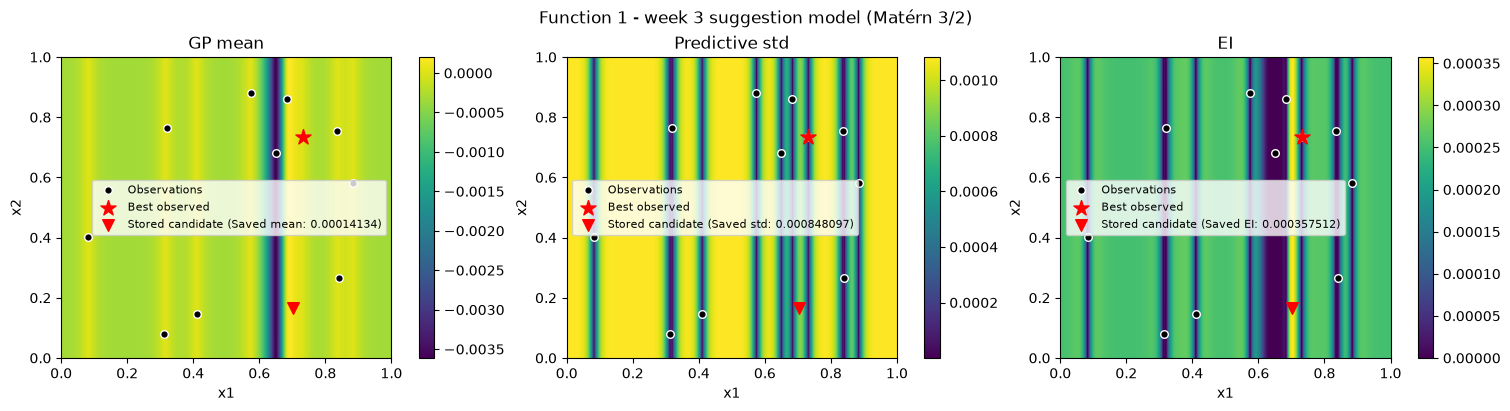

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


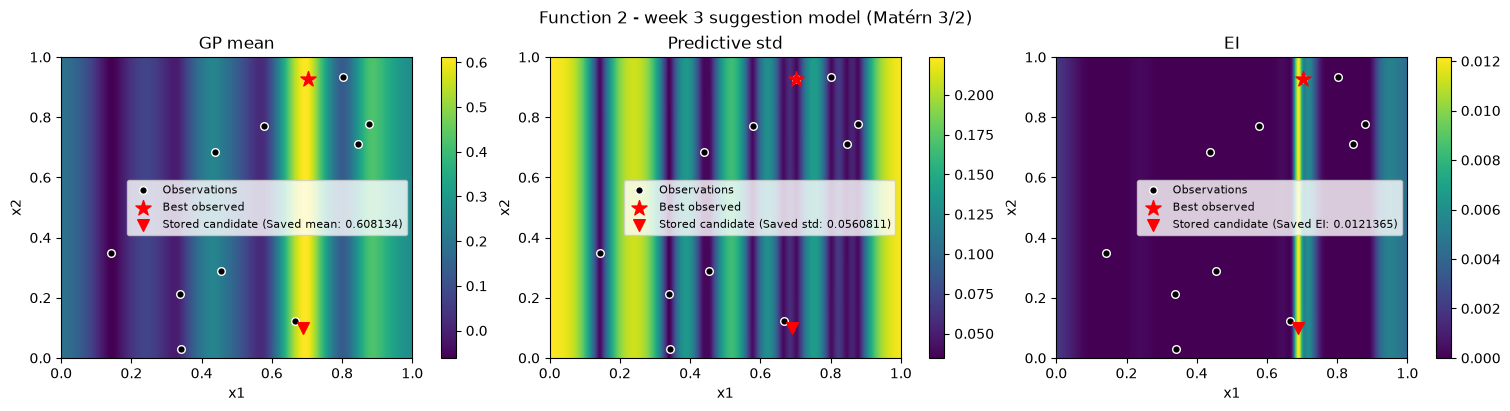

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


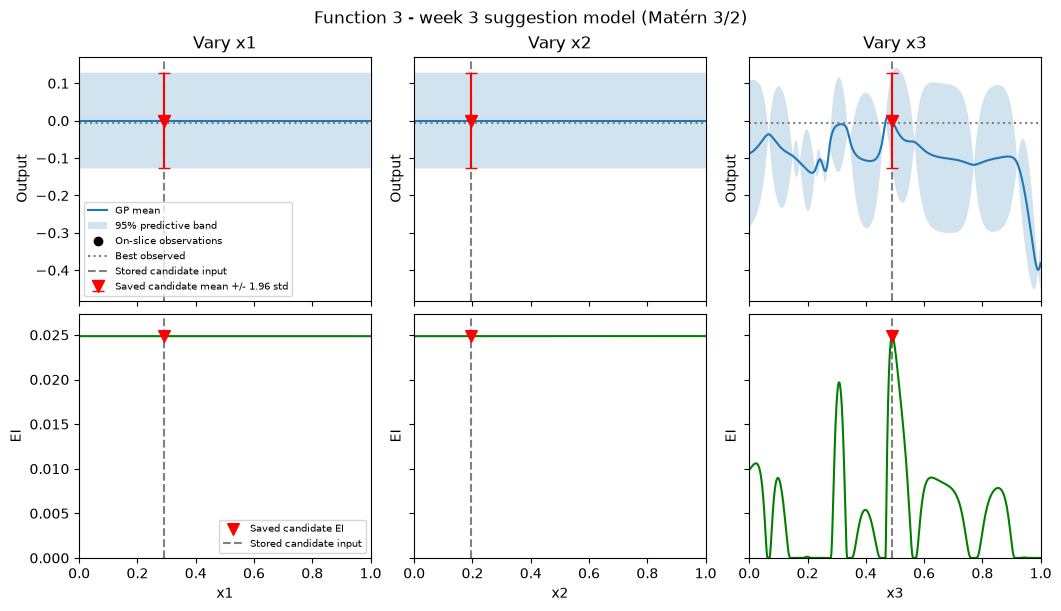

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


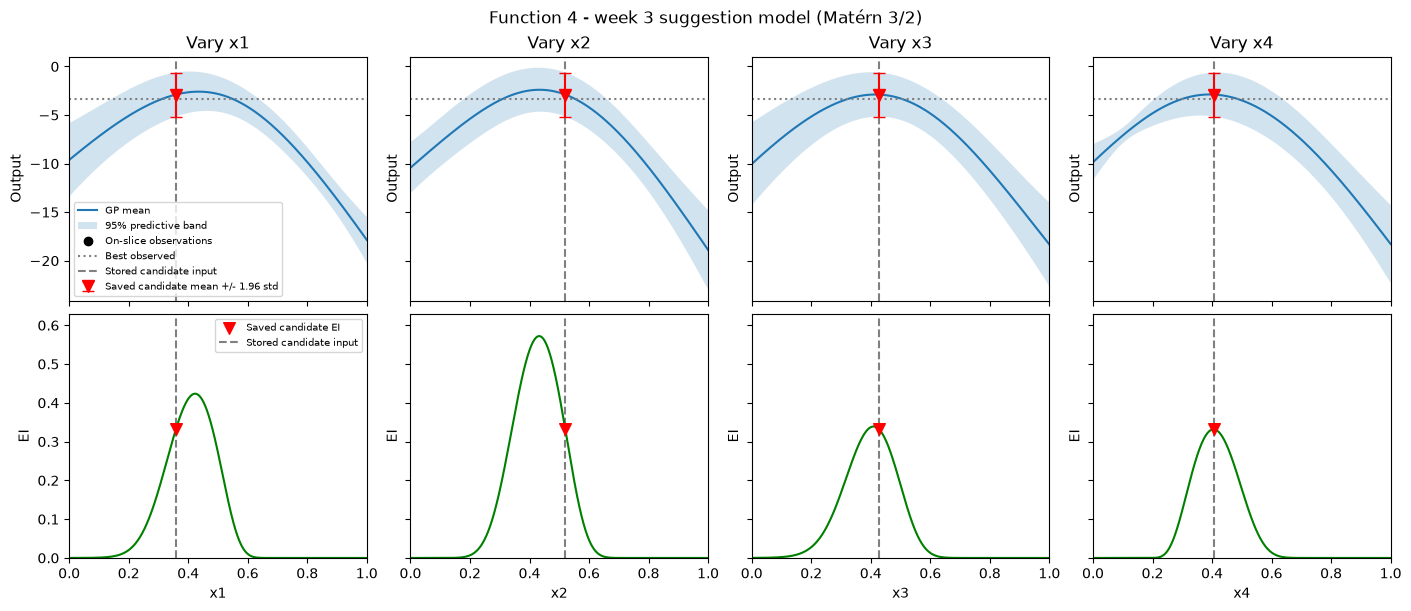

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


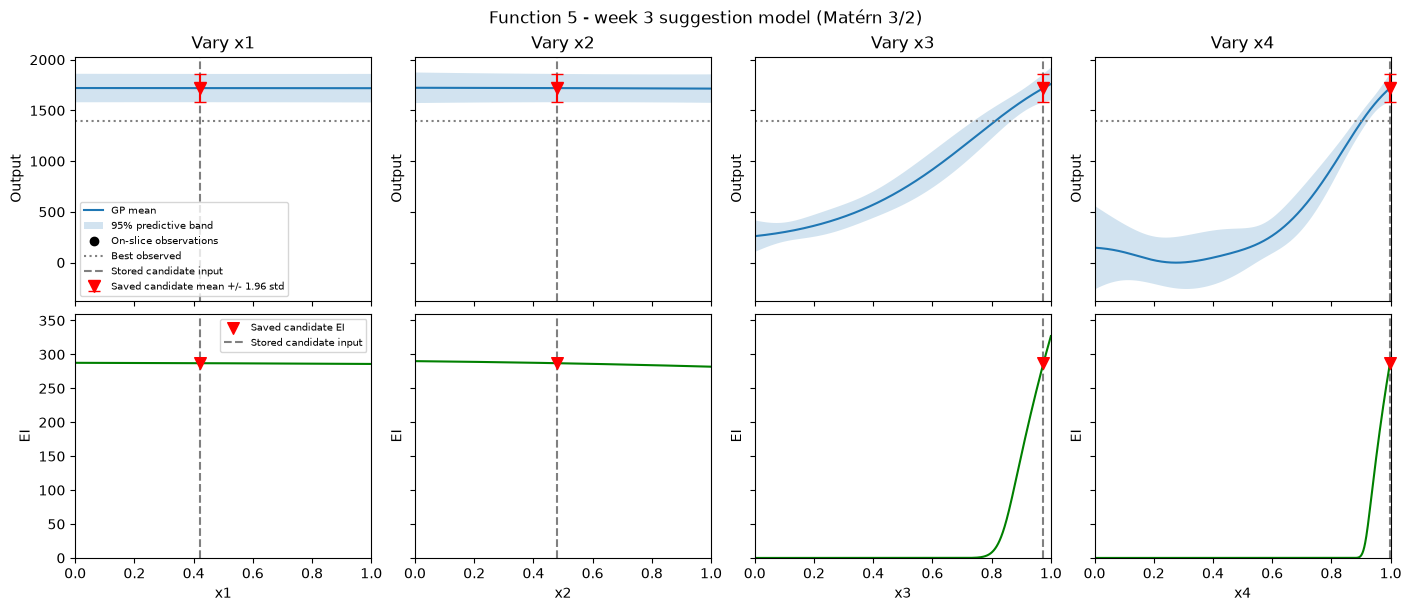

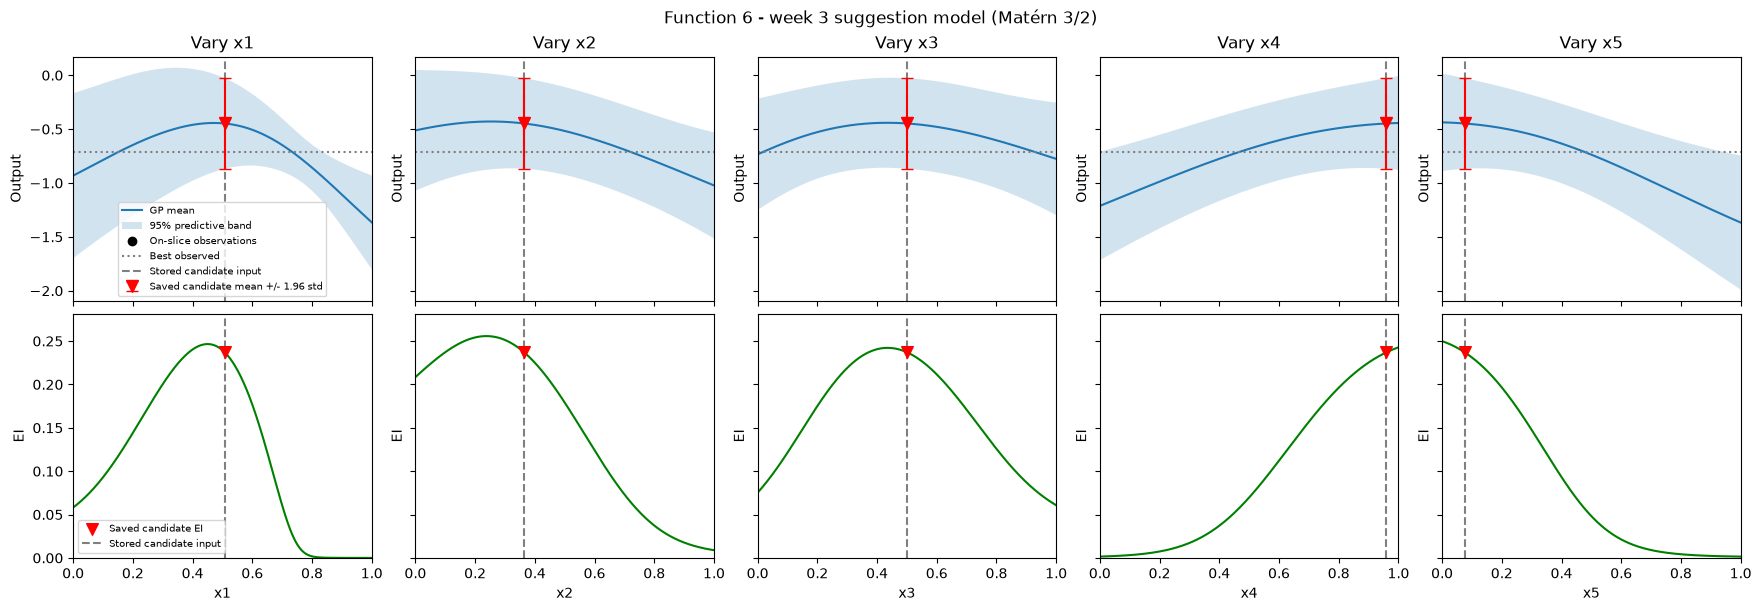

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


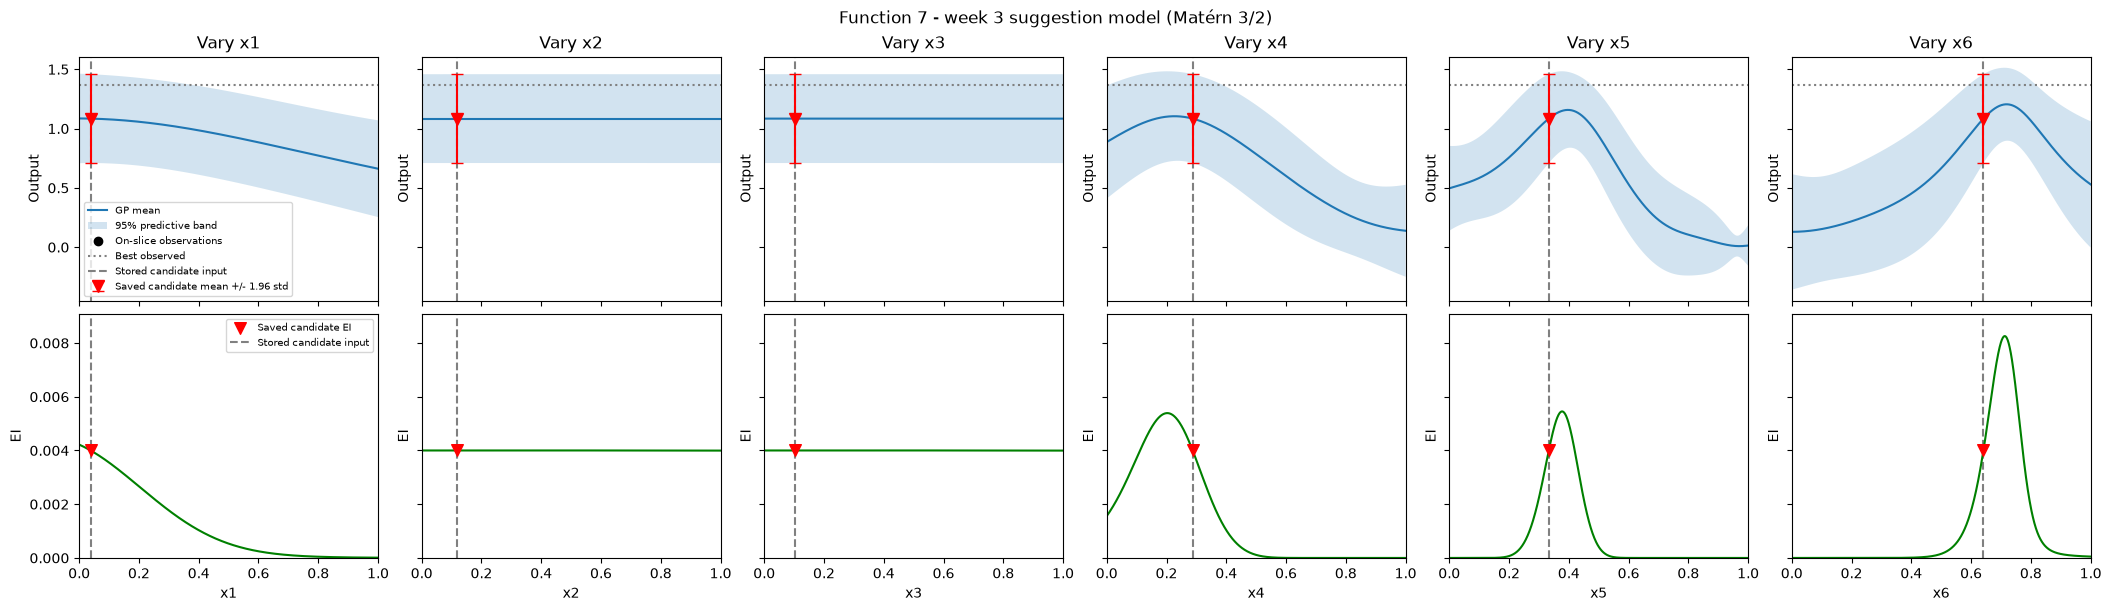

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 7 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


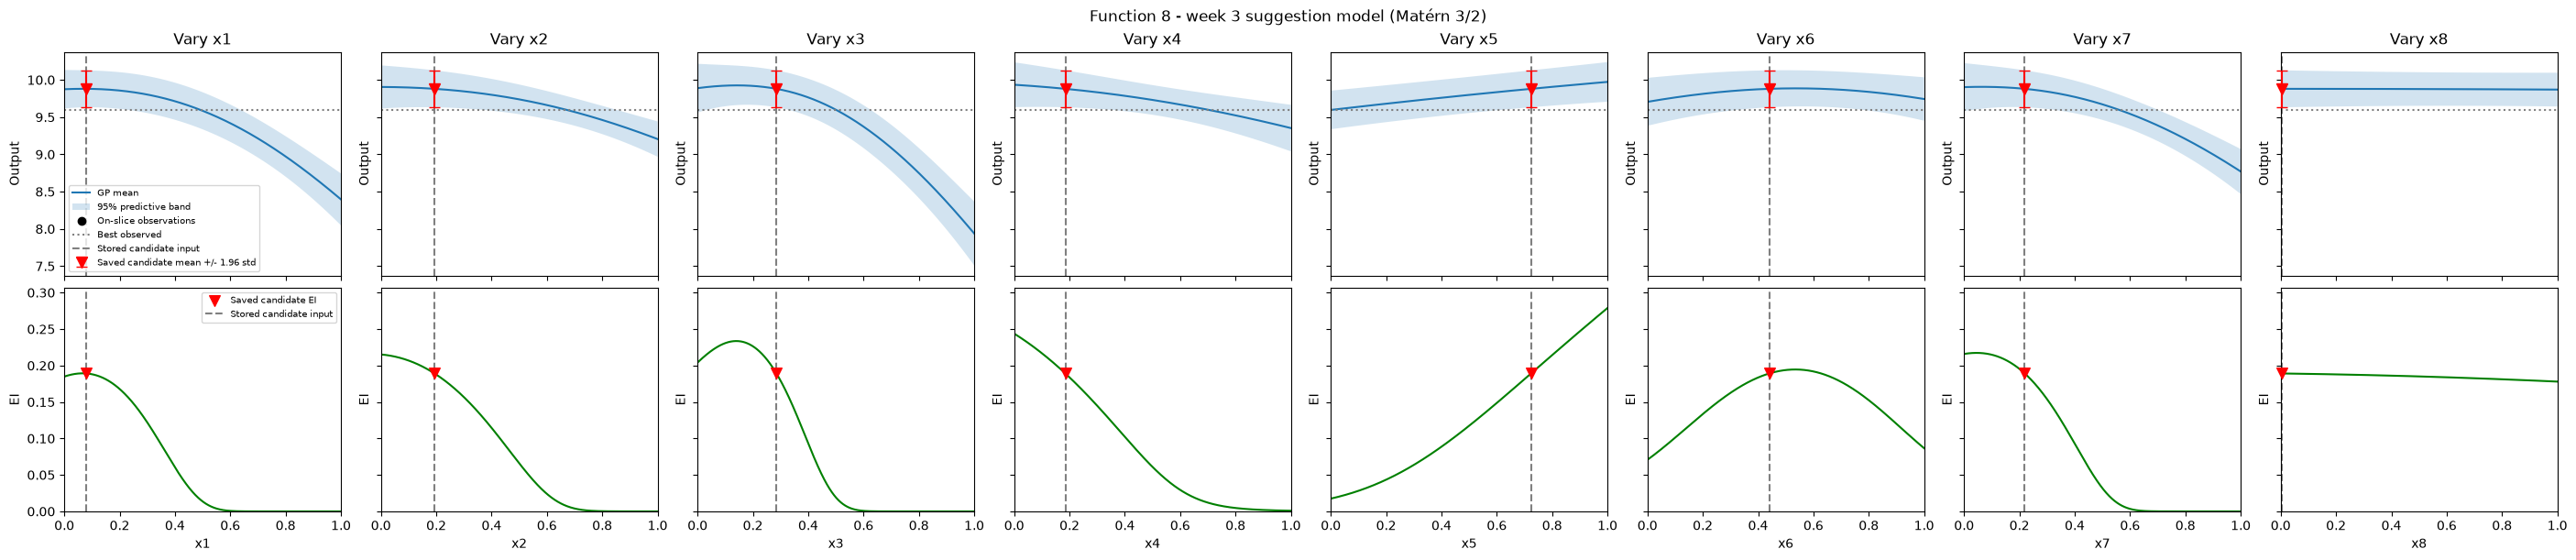

In [30]:
plot_function_ids = (1, 2, 3, 4, 5, 6, 7, 8)

for function_id in plot_function_ids:
    observations = load_observations(data_root, function_id, up_to_week=WEEK)
    kernel = make_matern_32_kernel(observations.dimension, LENGTH_CAPS[function_id])
    settings = stored_predictions["acquisition_settings"][function_id - 1]
    optimizer = BayesianOptimizer(
        observations,
        OptimisationConfig(budget=1, kernel=kernel, xi=settings["xi"], best=settings["best"]),
    )
    plot = plot_gp_2d if observations.dimension == 2 else plot_gp_slices
    figure, axes = plot(
        optimizer,
        n = 1000,
        candidate=stored_inputs[function_id - 1],
        expected_mean=stored_predictions["expected_outputs"][function_id - 1],
        expected_std=stored_predictions["stds"][function_id - 1],
        expected_ei=stored_predictions["acquisition_scores"][function_id - 1],
    )
    figure.suptitle(f"Function {function_id} - week {WEEK + 1} suggestion model (Matérn 3/2)")
    display(figure)
    plt.close(figure)

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


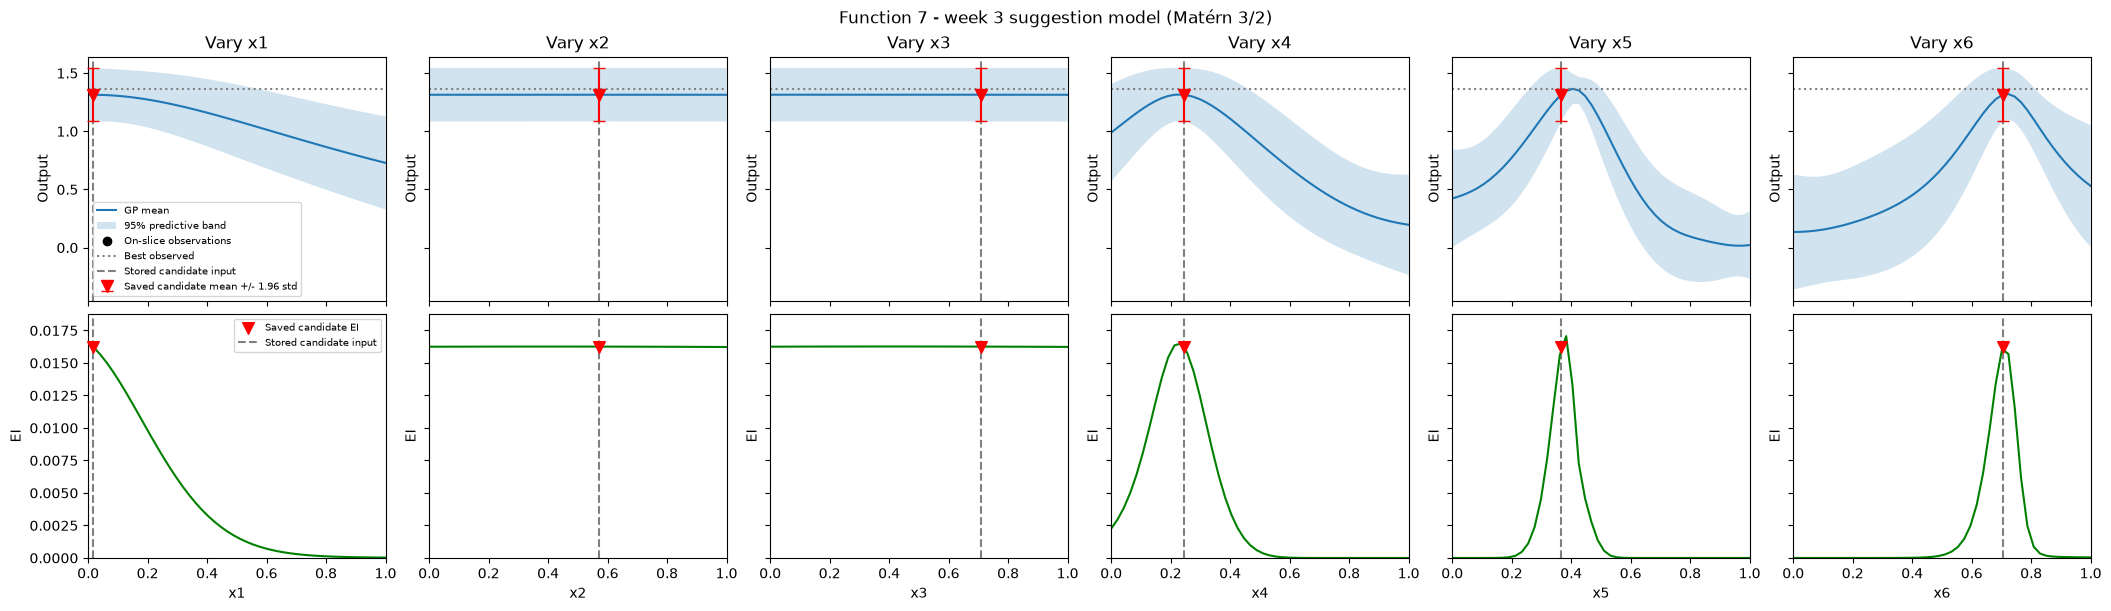

In [26]:
plot_function_ids = (7,)
N_CANDIDATES = 100000

for function_id in plot_function_ids:
    observations = load_observations(data_root, function_id, up_to_week=WEEK)
    kernel = make_matern_32_kernel(observations.dimension, LENGTH_CAPS[function_id])
    optimizer = BayesianOptimizer(
        observations,
        OptimisationConfig(
            budget=1, candidates=N_CANDIDATES, kernel=kernel, xi=XI_VALUES[function_id]
        ),
    )
    candidate, expected_mean, expected_std, acquisition_score = optimizer.suggest_with_prediction()
    plot = plot_gp_2d if observations.dimension == 2 else plot_gp_slices
    figure, axes = plot(
        optimizer,
        candidate=candidate,
        expected_mean=expected_mean,
        expected_std=expected_std,
        expected_ei=acquisition_score,
    )
    figure.suptitle(f"Function {function_id} - week {WEEK + 1} suggestion model (Matérn 3/2)")
    display(figure)
    plt.close(figure)